# Heston model — numerical validation

We implement the two pricing formulas from the report, **Gil-Pelaez** and **Lewis**, then validate them:

0. both formulas give the same price;
1. as $\xi \to 0$, the Heston price converges to the Black-Scholes price.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.stats import norm

## Parameters

We take $v_0 = \theta$: when $\xi = 0$, the variance then stays constant, equal to $\theta$, and the expected limit is Black-Scholes with $\sigma = \sqrt{\theta}$.

In [2]:
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05

kappa = 2.0
theta = 0.04
xi = 0.5
rho = -0.7
v0 = theta

## 1. Characteristic function

Formula from the report, implemented as is:

$$
b = \kappa - i\rho\xi u,\quad d = \sqrt{b^2 + \xi^2(u^2 + iu)},\quad g = \frac{b-d}{b+d},
$$
$$
D = \frac{b-d}{\xi^2}\cdot\frac{1-e^{-dT}}{1-g e^{-dT}},\qquad
C = iurT + \frac{\kappa\theta}{\xi^2}\Big[(b-d)T - 2\ln\frac{1-ge^{-dT}}{1-g}\Big],
$$
$$
\varphi(u) = \exp\big(C + D\,v_0 + iu\ln S_0\big).
$$

In [3]:
def heston_char(u, S0, T, r, kappa, theta, xi, rho, v0):
    b = kappa - 1j * rho * xi * u
    d = np.sqrt(b**2 + xi**2 * (u**2 + 1j * u))
    g = (b - d) / (b + d)

    D = (b - d) / xi**2 * (1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T))
    C = 1j * u * r * T + kappa * theta / xi**2 * (
        (b - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g))
    )
    return np.exp(C + D * v0 + 1j * u * np.log(S0))

In [4]:
phi_0 = heston_char(0.0, S0, T, r, kappa, theta, xi, rho, v0)
phi_mi = heston_char(-1j, S0, T, r, kappa, theta, xi, rho, v0)

print(f"phi(0)  = {phi_0.real:.10f}   (expected 1)")
print(f"phi(-i) = {phi_mi.real:.10f}   (expected S0*exp(rT) = {S0 * np.exp(r * T):.10f})")

phi(0)  = 1.0000000000   (expected 1)
phi(-i) = 105.1271096376   (expected S0*exp(rT) = 105.1271096376)


## 2. Call price: Gil-Pelaez

$$
C = S_0 P_1 - K e^{-rT} P_2, \qquad
P_j = \frac12 + \frac1\pi \int_0^{\infty} \mathrm{Re}\Big[\frac{e^{-iu\ln K}\varphi_j(u)}{iu}\Big]\,du,
$$
with $\varphi_2(u) = \varphi(u)$ and $\varphi_1(u) = \varphi(u-i)/\varphi(-i)$.

The integrand is bounded at $u = 0$, but takes the form $0/0$ there: we start the integral at a small $\varepsilon$.

In [5]:
def heston_call_price(S0, K, T, r, kappa, theta, xi, rho, v0, u_max=200.0):
    p = (S0, T, r, kappa, theta, xi, rho, v0)
    k = np.log(K)
    phi_mi = heston_char(-1j, *p)

    def integrand_P1(u):
        phi1 = heston_char(u - 1j, *p) / phi_mi
        return (np.exp(-1j * u * k) * phi1 / (1j * u)).real

    def integrand_P2(u):
        phi2 = heston_char(u, *p)
        return (np.exp(-1j * u * k) * phi2 / (1j * u)).real

    eps = 1e-8
    P1 = 0.5 + quad(integrand_P1, eps, u_max, limit=500)[0] / np.pi
    P2 = 0.5 + quad(integrand_P2, eps, u_max, limit=500)[0] / np.pi
    price = S0 * P1 - K * np.exp(-r * T) * P2
    return price, P1, P2

## 3. Call price: Lewis

$$
C = S_0 - \frac{\sqrt K e^{-rT}}{\pi}\int_0^\infty \mathrm{Re}\big[e^{-iu\ln K}\varphi(u - \tfrac i2)\big]\frac{du}{u^2+\frac14}.
$$

In [6]:
def lewis_call_price(S0, K, T, r, kappa, theta, xi, rho, v0, u_max=200.0):
    p = (S0, T, r, kappa, theta, xi, rho, v0)
    k = np.log(K)

    def integrand(u):
        return (np.exp(-1j * u * k) * heston_char(u - 0.5j, *p)).real / (u**2 + 0.25)

    integral = quad(integrand, 0.0, u_max, limit=500)[0]
    return S0 - np.sqrt(K) * np.exp(-r * T) / np.pi * integral

## 4. Black-Scholes and implied volatility

In [7]:
def bs_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def implied_vol(price, S0, K, T, r):
    return brentq(lambda s: bs_call(S0, K, T, r, s) - price, 1e-6, 5.0, xtol=1e-12)

## Validation 0 — Gil-Pelaez and Lewis give the same price

In [8]:
for K_test in [80.0, 90.0, 100.0, 110.0, 120.0]:
    price_gp, P1, P2 = heston_call_price(S0, K_test, T, r, kappa, theta, xi, rho, v0)
    price_lw = lewis_call_price(S0, K_test, T, r, kappa, theta, xi, rho, v0)
    print(f"K = {K_test:5.0f}   Gil-Pelaez: {price_gp:.8f}   Lewis: {price_lw:.8f}   diff: {abs(price_gp - price_lw):.1e}")

K =    80   Gil-Pelaez: 25.23676408   Lewis: 25.23676411   diff: 3.1e-08
K =    90   Gil-Pelaez: 17.14005510   Lewis: 17.14005511   diff: 1.8e-08
K =   100   Gil-Pelaez: 10.15462701   Lewis: 10.15462703   diff: 1.3e-08
K =   110   Gil-Pelaez: 4.86618257   Lewis: 4.86618258   diff: 1.3e-08
K =   120   Gil-Pelaez: 1.73823234   Lewis: 1.73823236   diff: 1.9e-08


The discrepancies, of order $10^{-8}$, come solely from the quadrature (truncation at `u_max`, starting at $\varepsilon$ for Gil-Pelaez).

## Validation 1 — Convergence to Black-Scholes as $\xi \to 0$

### Direct test

In [9]:
price_bs = bs_call(S0, K, T, r, np.sqrt(theta))
price_heston, P1, P2 = heston_call_price(S0, K, T, r, kappa, theta, xi=1e-4, rho=0.0, v0=v0)
price_lewis = lewis_call_price(S0, K, T, r, kappa, theta, xi=1e-4, rho=0.0, v0=v0)

print(f"BS: {price_bs:.6f}, Heston Gil-Pelaez (xi→0): {price_heston:.6f}, Heston Lewis (xi→0): {price_lewis:.6f}")

BS: 10.450584, Heston Gil-Pelaez (xi→0): 10.450584, Heston Lewis (xi→0): 10.450583


### Flattening of the smile

As $\xi \to 0$, the implied volatility smile should flatten towards the line $\sigma = \sqrt{\theta}$.

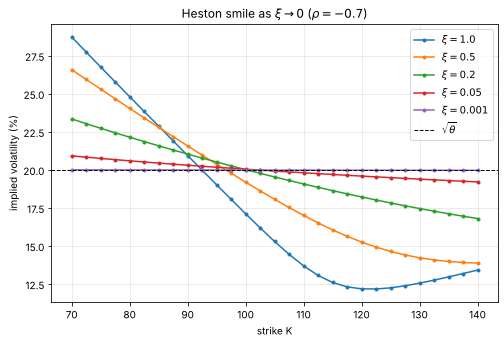

In [11]:
K_grid = np.linspace(70, 140, 29)

plt.figure(figsize=(8, 5))
for x in [1.0, 0.5, 0.2, 0.05, 0.001]:
    ivs = [implied_vol(lewis_call_price(S0, Kk, T, r, kappa, theta, x, rho, v0), S0, Kk, T, r) for Kk in K_grid]
    plt.plot(K_grid, np.array(ivs) * 100, "o-", ms=3, label=rf"$\xi = {x}$")

plt.axhline(np.sqrt(theta) * 100, color="k", ls="--", lw=1, label=r"$\sqrt{\theta}$")
plt.xlabel("strike K")
plt.ylabel("implied volatility (%)")
plt.title(rf"Heston smile as $\xi \to 0$ ($\rho = {rho}$)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()